<a href="https://colab.research.google.com/github/Arghantyr/Data-magic-dojo/blob/main/datasets/food-demand-forecasting/food-demand-forecasting-EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install netgraph

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [netgraph]


In [2]:
import kagglehub
import pandas as pd
import numpy as np
import os

# Import useful libraries
import matplotlib.pyplot as plt
import networkx as nx
from netgraph import Graph

In [3]:
# Download latest version
path = kagglehub.dataset_download("kannanaikkal/food-demand-forecasting")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'food-demand-forecasting' dataset.
Path to dataset files: /kaggle/input/food-demand-forecasting


In [4]:
!ls {path}

fulfilment_center_info.csv  sample_submission.csv  train.csv
meal_info.csv		    test.csv


In [5]:
full_path = "../kaggle/input/food-demand-forecasting"

train = pd.read_csv(os.path.join(path, "train.csv"))
test = pd.read_csv(os.path.join(path, "test.csv"))
meal_info = pd.read_csv(os.path.join(path, "meal_info.csv"))
fulfilment_center_info = pd.read_csv(os.path.join(path, "fulfilment_center_info.csv"))

# Meal info

In [6]:
meal_info.head()

,meal_id,category,cuisine
0,1885,Beverages,Thai
1,1993,Beverages,Thai
2,2539,Beverages,Thai
3,1248,Beverages,Indian
4,2631,Beverages,Indian


In [7]:
meal_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   meal_id   51 non-null     int64 
 1   category  51 non-null     object
 2   cuisine   51 non-null     object
dtypes: int64(1), object(2)
memory usage: 1.3+ KB


In [8]:
meal_info.meal_id.nunique(), meal_info.category.nunique(), meal_info.cuisine.nunique()

for col in meal_info.columns:
    unique_items = ''
    tmp=[]
    for n, item in enumerate(meal_info[col].sort_values().unique().astype(str).tolist()):
        if (n+1)%10==0:
            unique_items += ', '.join(tmp) + '\n'
            tmp = []
        else:
            tmp.append(item)
    unique_items += ', '.join(tmp) + '\n'

    print(f"{col}:\n\tUnique values ({meal_info[col].nunique()}): {unique_items}\n")

meal_id:
	Unique values (51): 1062, 1109, 1198, 1207, 1216, 1230, 1247, 1248, 1311
1445, 1525, 1543, 1558, 1571, 1727, 1754, 1770, 1778
1847, 1878, 1885, 1902, 1962, 1971, 1993, 2104, 2126
2290, 2304, 2306, 2322, 2444, 2490, 2492, 2494, 2539
2577, 2581, 2631, 2640, 2664, 2704, 2707, 2760, 2826
2956


category:
	Unique values (14): Beverages, Biryani, Desert, Extras, Fish, Other Snacks, Pasta, Pizza, Rice Bowl
Sandwich, Seafood, Soup, Starters


cuisine:
	Unique values (4): Continental, Indian, Italian, Thai




In [9]:
meal_info.groupby(['category', 'cuisine']).count().sort_values(by='cuisine', ascending=False)

,,meal_id
category,cuisine,
Other Snacks,Thai,3
Extras,Thai,3
Soup,Thai,3
Starters,Thai,3
Beverages,Thai,3
Pasta,Italian,3
Salad,Italian,3
Sandwich,Italian,3
Beverages,Italian,3


# Fulfilment center info

In [10]:
fulfilment_center_info.head(10)

,center_id,city_code,region_code,center_type,op_area
0,11,679,56,TYPE_A,3.7
1,13,590,56,TYPE_B,6.7
2,124,590,56,TYPE_C,4.0
3,66,648,34,TYPE_A,4.1
4,94,632,34,TYPE_C,3.6
5,64,553,77,TYPE_A,4.4
6,129,593,77,TYPE_A,3.9
7,139,693,34,TYPE_C,2.8
8,88,526,34,TYPE_A,4.1
9,143,562,77,TYPE_B,3.8


In [11]:
fulfilment_center_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   center_id    77 non-null     int64  
 1   city_code    77 non-null     int64  
 2   region_code  77 non-null     int64  
 3   center_type  77 non-null     object 
 4   op_area      77 non-null     float64
dtypes: float64(1), int64(3), object(1)
memory usage: 3.1+ KB


In [12]:
for col in fulfilment_center_info.columns:
    unique_items = ''
    tmp=[]
    for n, item in enumerate(fulfilment_center_info[col].sort_values().unique().astype(str).tolist()):
        if (n+1)%10==0:
            unique_items += ', '.join(tmp) + '\n'
            tmp = []
        else:
            tmp.append(item)
    unique_items += ', '.join(tmp) + '\n'

    print(f"{col}:\n\tUnique values ({fulfilment_center_info[col].nunique()}): {unique_items}\n")

center_id:
	Unique values (77): 10, 11, 13, 14, 17, 20, 23, 24, 26
29, 30, 32, 34, 36, 39, 41, 42, 43
51, 52, 53, 55, 57, 58, 59, 61, 64
66, 67, 68, 72, 73, 74, 75, 76, 77
81, 83, 86, 88, 89, 91, 92, 93, 94
99, 101, 102, 104, 106, 108, 109, 110, 113
126, 129, 132, 137, 139, 143, 145, 146, 149
153, 157, 161, 162, 174, 177, 186


city_code:
	Unique values (51): 456, 461, 473, 478, 485, 515, 517, 522, 526
553, 556, 561, 562, 576, 577, 579, 590, 593
599, 602, 604, 609, 614, 615, 620, 628, 632
647, 648, 649, 651, 654, 658, 659, 675, 676
680, 683, 685, 693, 695, 698, 699, 700, 702
713


region_code:
	Unique values (8): 23, 34, 35, 56, 71, 77, 85, 93


center_type:
	Unique values (3): TYPE_A, TYPE_B, TYPE_C


op_area:
	Unique values (30): 0.9, 1.9, 2.0, 2.4, 2.7, 2.8, 2.9, 3.0, 3.2
3.5, 3.6, 3.7, 3.8, 3.9, 4.0, 4.1, 4.2, 4.4
4.6, 4.7, 4.8, 5.0, 5.1, 5.3, 5.6, 6.3, 6.7





# Podział na regiony i centra

Warto zwizualizować centra realizacyjne tak, żeby było widać, które ile miast obsługuje, którego typu jest, itd.

In [13]:
center_groups = fulfilment_center_info.groupby(['center_type', 'region_code', 'city_code'])['center_id'].count()

center_groups

center_type  region_code  city_code
TYPE_A       23           698          1
             34           461          1
                          526          3
                          576          1
                          602          1
                                      ..
TYPE_C       77           515          1
                          541          1
                          680          1
                          695          1
             85           699          2
Name: center_id, Length: 63, dtype: int64

In [14]:
from collections import Counter

Counter(center_groups)

Counter({1: 55, 3: 2, 2: 4, 4: 2})

Every city is connected to at least 1 fulfillment center and 10 are connected to at least 2 centers.

# Get a glimpse of the training data

In [15]:
train.head(10)

,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders
0,1379560,1,55,1885,136.83,152.29,0,0,177
1,1466964,1,55,1993,136.83,135.83,0,0,270
2,1346989,1,55,2539,134.86,135.86,0,0,189
3,1338232,1,55,2139,339.50,437.53,0,0,54
4,1448490,1,55,2631,243.50,242.50,0,0,40
5,1270037,1,55,1248,251.23,252.23,0,0,28
6,1191377,1,55,1778,183.36,184.36,0,0,190
7,1499955,1,55,1062,182.36,183.36,0,0,391
8,1025244,1,55,2707,193.06,192.06,0,0,472
9,1054194,1,55,1207,325.92,384.18,0,1,676


We have the meal_id and center_id, so we can trace popularity of each of food category and cuisine as well. Moreover, the checkout_price and base_price often differ. We don't know the reason, but we could compute the difference to know more.

In [19]:
train['price_diff'] = train['checkout_price'] - train['base_price']
train.head()

,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,price_diff
0,1379560,1,55,1885,136.83,152.29,0,0,177,-15.46
1,1466964,1,55,1993,136.83,135.83,0,0,270,1.00
2,1346989,1,55,2539,134.86,135.86,0,0,189,-1.00
3,1338232,1,55,2139,339.50,437.53,0,0,54,-98.03
4,1448490,1,55,2631,243.50,242.50,0,0,40,1.00


By calculating the difference as `checkout - base` we can get a glimpse of assumed discounts or additional costs, e.g., packaging. The provenance remains unknown, though.

The second thing we should calculate is the `income`, but before that, lets look into the `base_price` to see if it is proportional to the `num_orders` or depends on other parameters.

In [34]:
train.loc[(train['meal_id']==1885), :]

,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,price_diff
0,1379560,1,55,1885,136.83,152.29,0,0,177,-15.46
33,1040403,1,24,1885,136.83,136.83,0,0,1498,0.00
77,1103215,1,11,1885,136.83,136.83,0,0,959,0.00
119,1034383,1,83,1885,121.31,120.31,0,1,1025,1.00
157,1118999,1,32,1885,114.52,113.52,0,1,445,1.00
...,...,...,...,...,...,...,...,...,...,...
456329,1375154,145,23,1885,160.11,160.11,0,0,501,0.00
456373,1201633,145,86,1885,158.14,159.14,0,0,432,-1.00
456414,1420447,145,68,1885,119.31,121.31,0,0,337,-2.00
456457,1017944,145,51,1885,159.14,158.14,0,0,1188,1.00


For a selected meal, we see that the `base_price` varies between fulfillment centers, weeks and possibly the number of orders. LEts do this properly and see how `base_price` correlates with each of the parameters.

In [39]:
train.loc[(train['meal_id']==1885), train.columns[1:-1]].corr()

,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders
week,1.000000,-0.004718,NaN,0.172564,0.145092,-0.110225,-0.110228,0.001013
center_id,-0.004718,1.000000,NaN,-0.241894,-0.261424,0.028881,0.006122,-0.102978
meal_id,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
checkout_price,0.172564,-0.241894,NaN,1.000000,0.877065,-0.250074,0.071005,0.345263
base_price,0.145092,-0.261424,NaN,0.877065,1.000000,-0.131277,0.102587,0.388745
emailer_for_promotion,-0.110225,0.028881,NaN,-0.250074,-0.131277,1.000000,0.087116,0.069023
homepage_featured,-0.110228,0.006122,NaN,0.071005,0.102587,0.087116,1.000000,0.336134
num_orders,0.001013,-0.102978,NaN,0.345263,0.388745,0.069023,0.336134,1.000000


There is some weak correlation with respect to some parameters, but we also get some values that likely have no sense, e.g., correlation between `center_id`, which could easily be given a name instead of a numerical value. Lets focus on a single week and see how that affects the `base price`.

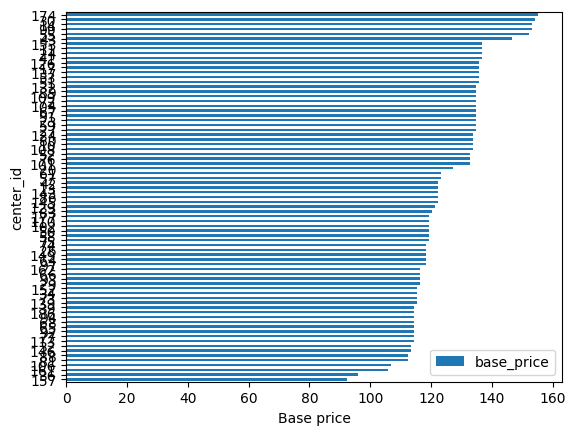

In [61]:
train.loc[(train['meal_id']==1885) & (train['week']==1), ['center_id', 'base_price']].sort_values(by='base_price').plot(
    x='center_id',
    kind='barh'
)
plt.xlabel('Base price');

On a given week, a given meal has a similar or even the same `base_price` among several fulfilment centers. Lets focus on a single center for now to see if there are changes with respect to other parameters.

In [66]:
train.loc[
    (
        train['meal_id']==1885
    ) & (
        train['week']==1
    ) & (
        train['center_id']==55
    ), :]

,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,price_diff
0,1379560,1,55,1885,136.83,152.29,0,0,177,-15.46


Huh... the meal price is fixed for our selected center for a given week.

In [67]:
train.loc[
    (
        train['meal_id']==1885
    ) & (
        train['week']==1
    ) & (
        train['center_id']!=-1
    ), :]

,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,price_diff
0,1379560,1,55,1885,136.83,152.29,0,0,177,-15.46
33,1040403,1,24,1885,136.83,136.83,0,0,1498,0.00
77,1103215,1,11,1885,136.83,136.83,0,0,959,0.00
119,1034383,1,83,1885,121.31,120.31,0,1,1025,1.00
157,1118999,1,32,1885,114.52,113.52,0,1,445,1.00
...,...,...,...,...,...,...,...,...,...,...
2719,1111451,1,23,1885,135.83,134.83,0,1,972,1.00
2763,1027820,1,86,1885,136.83,122.25,0,1,918,14.58
2800,1452232,1,68,1885,113.49,114.49,0,1,433,-1.00
2839,1032584,1,51,1885,134.86,135.83,0,1,1323,-0.97


For the first week we get 77 rows, matching the number of fulfillment centers. Lets see if that is the case in later weeks as well.

<Axes: xlabel='week'>

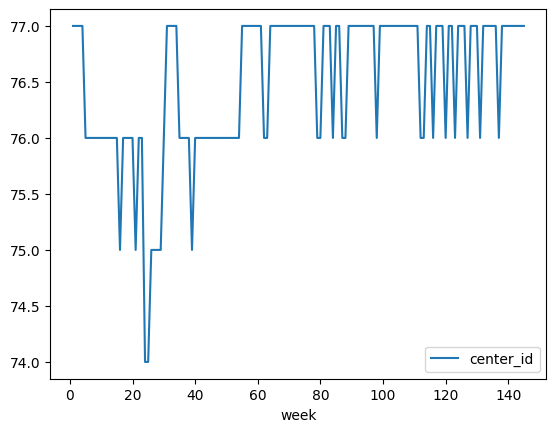

In [78]:
train.loc[
    (
        train['meal_id']==1885
    ) & (
        train['center_id']!=-1
    ), ['week', 'center_id']].groupby('week').count().plot()

Hmm... In some weeks several centers are not represented for that particular `meal_id`. Lets see if the centers are equally represented throught the time scope.

<Axes: xlabel='week'>

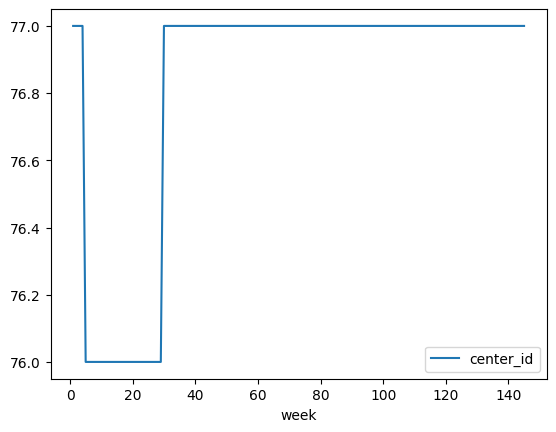

In [84]:
train[['week', 'center_id']].drop_duplicates().groupby('week').count().plot()

For a given range some fulfilment center(s) are not represented.

<Axes: xlabel='week'>

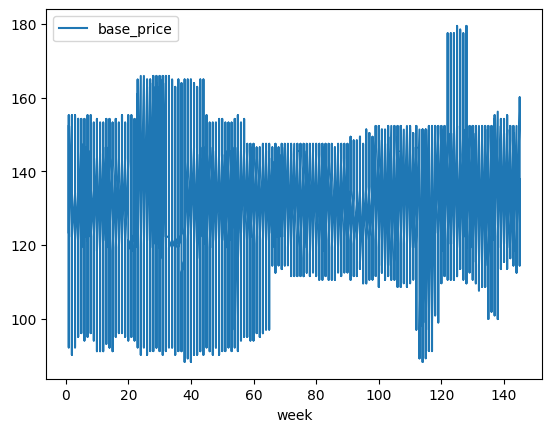

In [33]:
train.loc[(train['meal_id']==1885), ['week', 'base_price']].plot(
    x='week'
)

In [24]:
train[(train['meal_id']==1885) & (train['center_id']==55)]

,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,price_diff
0,1379560,1,55,1885,136.83,152.29,0,0,177,-15.46
2922,1018704,2,55,1885,135.83,152.29,0,0,323,-16.46
5818,1196273,3,55,1885,132.92,133.92,0,0,96,-1.00
8717,1116527,4,55,1885,135.86,134.86,0,0,163,1.00
11606,1343872,5,55,1885,146.50,147.50,0,0,215,-1.00
...,...,...,...,...,...,...,...,...,...,...
440172,1236628,141,55,1885,150.35,150.35,0,0,107,0.00
443435,1436751,142,55,1885,148.47,148.47,0,0,121,0.00
446673,1161827,143,55,1885,150.35,150.35,0,0,176,0.00
449978,1292806,144,55,1885,150.35,152.35,0,0,162,-2.00


In [25]:
train[(train['meal_id']==1885) & (train['center_id']==55)].apply(lambda row: row['base_price']/row['num_orders'], axis=1)

,0
0,0.860395
2922,0.471486
5818,1.395000
8717,0.827362
11606,0.686047
...,...
440172,1.405140
443435,1.227025
446673,0.854261
449978,0.940432


<Axes: >

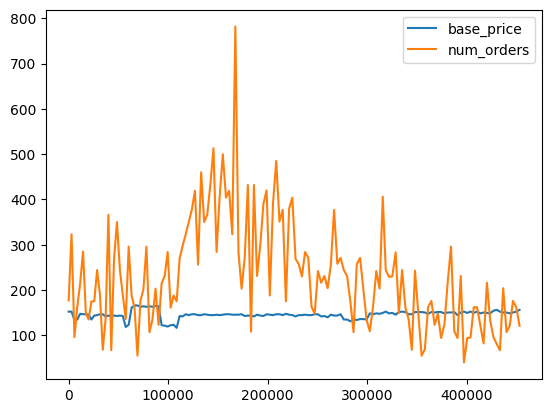

In [30]:
train.loc[(train['meal_id']==1885) & (train['center_id']==55), ['base_price', 'num_orders']].plot()

In [16]:
train.groupby(['week', 'meal_id']).mean()

id  center_id  checkout_price  base_price  \
week meal_id                                                        
1    1062     1.263689e+06  83.142857      176.202727  176.202727   
     1109     1.233601e+06  83.142857      265.711948  289.463636   
     1198     1.248668e+06  65.384615      176.016154  203.690385   
     1207     1.233419e+06  82.041096      320.114658  350.067945   
     1216     1.254643e+06  83.242424      417.256364  436.736212   
...                    ...        ...             ...         ...   
145  2707     1.246571e+06  83.142857      218.343766  222.084805   
     2760     1.238502e+06  82.563380      175.040704  252.814507   
     2826     1.242649e+06  83.142857      350.731039  350.588182   
     2867     1.230558e+06  84.153846      719.729808  726.951154   
     2956     1.182009e+06  77.600000      617.094000  616.919000   

              emailer_for_promotion  homepage_featured  num_orders  
week meal_id                                                        
1    1062                  0.000000           0.000000  375.883117  
     1109                  0.467532           0.012987  830.961039  
     1198                  0.000000           0.038462  207.346154  
     1207                  0.054795           0.205479  286.205479  
     1216                  0.000000           0.181818   59.939394  
...                             ...                ...         ...  
145  2707                  0.000000           0.000000  517.311688  
     2760                  0.000000           0.352113  230.845070  
     2826                  0.000000           0.000000  333.844156  
     2867                  0.000000           0.115385   31.346154  
     2956                  0.000000           0.000000   82.475000  

[7173 rows x 7 columns]

In [17]:
train.groupby(['week', 'center_id', 'meal_id']).mean()

id  checkout_price  base_price  \
week center_id meal_id                                          
1    10        1062     1436842.0          181.39      181.39   
               1109     1142165.0          231.86      276.48   
               1198     1421626.0          129.04      196.00   
               1207     1260561.0          322.07      382.18   
               1216     1411421.0          455.93      454.93   
...                           ...             ...         ...   
145  186       2704     1420415.0          321.13      319.13   
               2707     1013011.0          196.00      195.00   
               2760     1082117.0          182.36      261.93   
               2826     1311738.0          327.92      327.92   
               2867     1123781.0          727.53      727.53   

                        emailer_for_promotion  homepage_featured  num_orders  
week center_id meal_id                                                        
1    10        1062                       0.0                0.0       865.0  
               1109                       1.0                0.0      2672.0  
               1198                       0.0                0.0       269.0  
               1207                       0.0                0.0       769.0  
               1216                       0.0                0.0        54.0  
...                                       ...                ...         ...  
145  186       2704                       0.0                0.0        67.0  
               2707                       0.0                0.0       175.0  
               2760                       0.0                0.0        96.0  
               2826                       0.0                0.0       162.0  
               2867                       0.0                0.0        28.0  

[456548 rows x 6 columns]